# Fitting a Gaussian emission line to a mock galaxy spectrum

This example shows the basic `bff` workflow:

1. Make a mock spectrum: a flat continuum plus a Gaussian H$\alpha$ emission line, with noise.
2. Write a log-likelihood function, `lnlike(data, params)`.
3. Describe the free parameters and their priors in a `fit_instructions` dictionary.
4. Run the nested-sampling fit (MultiNest, through `pymultinest`).
5. Look at the posterior, and reload it later with `bff.posterior`.

**Requirements:** `bff` must be installed, e.g. by running `pip install .[examples]` from the repository root. This also installs `matplotlib` and `corner`. `pymultinest` also needs the MultiNest library installed separately.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import bff

np.random.seed(42)

## 1. A mock spectrum

The spectrum covers 6400–6700 Å at 1 Å per pixel. It has a flat continuum, one Gaussian emission line, and Gaussian noise with a constant 1σ uncertainty per pixel. Fluxes are in arbitrary units (think $10^{-17}\,\mathrm{erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$).

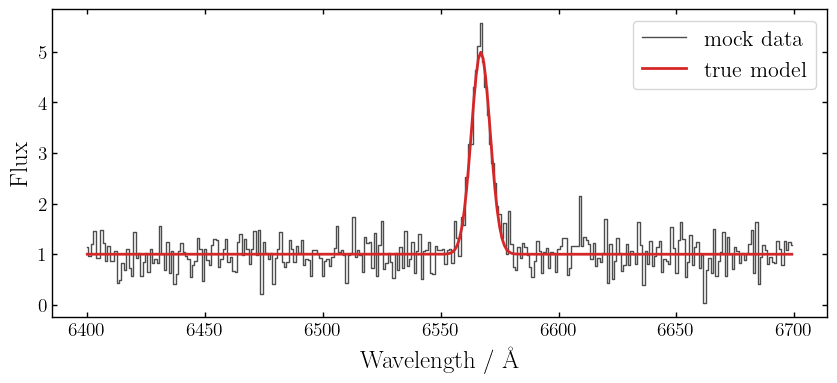

In [2]:
def gaussian_line_model(wavelengths, continuum, flux, centre, sigma):
    """ Flat continuum plus a Gaussian line with integrated flux `flux`. """
    line = flux / (np.sqrt(2 * np.pi) * sigma) * np.exp(-0.5 * ((wavelengths - centre) / sigma)**2)
    return continuum + line


truth = {"continuum": 1.0, "flux": 40.0, "centre": 6567.0, "sigma": 4.0}

wavelengths = np.arange(6400., 6700., 1.)
noise = 0.3 * np.ones_like(wavelengths)

true_spectrum = gaussian_line_model(wavelengths, **truth)
flux = true_spectrum + noise * np.random.randn(wavelengths.size)

# bff passes this object to your likelihood function unchanged, so it can be anything.
data = {"wavelengths": wavelengths, "flux": flux, "flux_err": noise}

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(wavelengths, flux, where="mid", color="0.3", lw=1, label="mock data")
ax.plot(wavelengths, true_spectrum, color="C3", lw=2, label="true model")
ax.set_xlabel(r"Wavelength / $\mathrm{\AA}$")
ax.set_ylabel("Flux")
ax.legend()
plt.show()

## 2. The likelihood

`bff` calls `lnlike(data, params)` for each sample. `params` is a copy of `fit_instructions` in which every fitted parameter has been replaced by its current value, nested the same way. The likelihood below is the usual Gaussian (χ²) likelihood. It keeps the normalisation term so that the Bayesian evidence (`lnz`) means something.

In [3]:
def lnlike(data, params):
    model = gaussian_line_model(data["wavelengths"],
                                params["continuum"],
                                params["line"]["flux"],
                                params["line"]["centre"],
                                params["line"]["sigma"])

    chisq = np.sum(((data["flux"] - model) / data["flux_err"])**2)
    norm = np.sum(np.log(2 * np.pi * data["flux_err"]**2))

    return -0.5 * (chisq + norm)

## 3. Fit instructions and priors

The `fit_instructions` dictionary says what to fit:

* A **tuple** `(low, high)` makes a parameter free, with prior limits `low` and `high`. The prior is uniform unless you say otherwise.
* `"<name>_prior"` picks another prior shape from `bff.prior`: `"uniform"`, `"log_10"`, `"log_e"`, `"pow_10"`, `"recip"`, `"recipsq"` or `"Gaussian"`.
* `"<name>_prior_<hyper>"` sets that prior's hyper-parameters, e.g. `mu` and `sigma` for `"Gaussian"`.
* You can nest parameters one level deep in a sub-dictionary (here `"line"`). Internally they're called `"line:flux"` and so on.
* Any value that isn't a tuple stays fixed and is passed to `lnlike` unchanged.

Here the line flux gets a log-uniform prior. The line centre gets a Gaussian prior around the rest-frame H$\alpha$ wavelength, as if we had a rough redshift.

In [4]:
fit_instructions = {
    "continuum": (0., 2.),

    "line": {
        "flux": (1., 500.),
        "flux_prior": "log_10",

        "centre": (6540., 6590.),
        "centre_prior": "Gaussian",
        "centre_prior_mu": 6563.,
        "centre_prior_sigma": 10.,

        "sigma": (0.5, 20.),
    },
}

## 4. Run the fit

`bff.fit` takes an ID, the data, the likelihood function and the fit instructions. Outputs are saved to `bff/<run>/<ID>.h5` under the current working directory.

If that file already exists, the results are loaded instead of fitting again. Delete the file, or change the ID, to start over.

`use_MPI=False` is needed when running inside a notebook. For big fits, run a script under `mpirun` instead.

In [5]:
fitter = bff.fit("mock_halpha", data, lnlike, fit_instructions)

fitter.fit(n_live=400, verbose=False, use_MPI=False)


Performing fit with ID: mock_halpha

 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    4
 *****************************************************



Completed in 0.9 seconds.
 ln(ev)=  -74.474997844662894      +/-  0.18786403607957811     
 Total Likelihood Evaluations:        24721
 Sampling finished. Exiting MultiNest

Parameter                          Posterior percentiles
                                16th       50th       84th
----------------------------------------------------------
continuum                      0.978      0.995      1.012
line:centre                 6566.685   6566.845   6567.001
line:flux                     39.676     41.161     42.589
line:sigma                     3.862      4.034      4.216




## 5. Results

After fitting, `fitter.posterior` maps each fitted parameter name to an array of posterior samples. `fitter.results` holds the full equal-weight samples (`samples2d`), the log-likelihoods, and the log-evidence `lnz`.

In [6]:
true_values = {"continuum": truth["continuum"], "line:centre": truth["centre"],
               "line:flux": truth["flux"], "line:sigma": truth["sigma"]}

print(f"{'Parameter':<14}{'truth':>10}{'16th':>10}{'50th':>10}{'84th':>10}")
for name in fitter.params:
    p16, p50, p84 = np.percentile(fitter.posterior[name], (16, 50, 84))
    print(f"{name:<14}{true_values[name]:>10.2f}{p16:>10.2f}{p50:>10.2f}{p84:>10.2f}")

print(f"\nln(evidence) = {fitter.results['lnz']:.2f} ± {fitter.results['lnz_err']:.2f}")

Parameter          truth      16th      50th      84th
continuum           1.00      0.98      0.99      1.01
line:centre      6567.00   6566.70   6566.83   6566.99
line:flux          40.00     39.66     41.21     42.68
line:sigma          4.00      3.86      4.03      4.22

ln(evidence) = -74.47 ± 0.19


### Posterior model compared with the data

Next we compute the model for each posterior sample, and plot the median and the 16th–84th percentile band over the data, with residuals underneath.

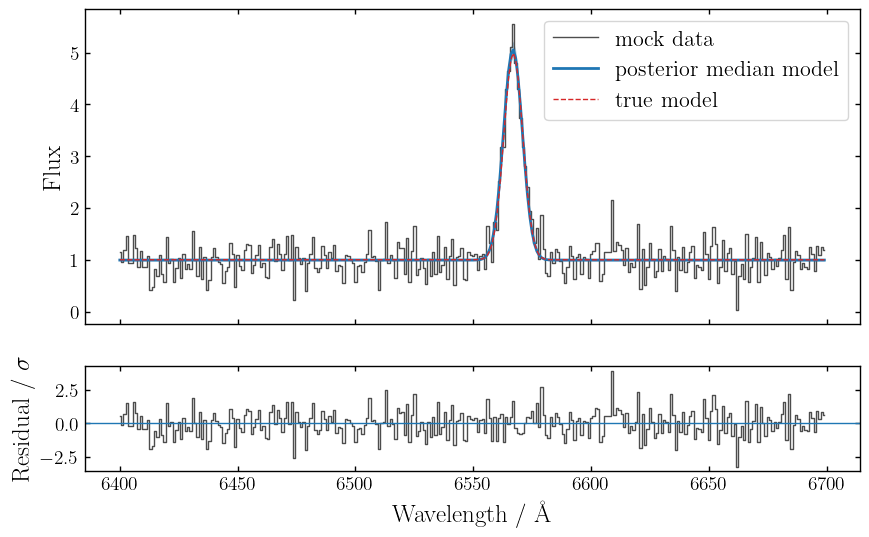

In [7]:
models = np.array([
    gaussian_line_model(wavelengths,
                        fitter.posterior["continuum"][i],
                        fitter.posterior["line:flux"][i],
                        fitter.posterior["line:centre"][i],
                        fitter.posterior["line:sigma"][i])
    for i in range(fitter.n_posterior)
])
m16, m50, m84 = np.percentile(models, (16, 50, 84), axis=0)

fig, (ax, rax) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})

ax.step(wavelengths, flux, where="mid", color="0.3", lw=1, label="mock data")
ax.fill_between(wavelengths, m16, m84, color="C0", alpha=0.4, lw=0)
ax.plot(wavelengths, m50, color="C0", lw=2, label="posterior median model")
ax.plot(wavelengths, true_spectrum, color="C3", lw=1, ls="--", label="true model")
ax.set_ylabel("Flux")
ax.legend()

rax.step(wavelengths, (flux - m50) / noise, where="mid", color="0.3", lw=1)
rax.axhline(0., color="C0", lw=1)
rax.set_xlabel(r"Wavelength / $\mathrm{\AA}$")
rax.set_ylabel(r"Residual / $\sigma$")
plt.show()

### Corner plot

This uses the [`corner`](https://corner.readthedocs.io) package (`pip install corner`). The red lines mark the true values.

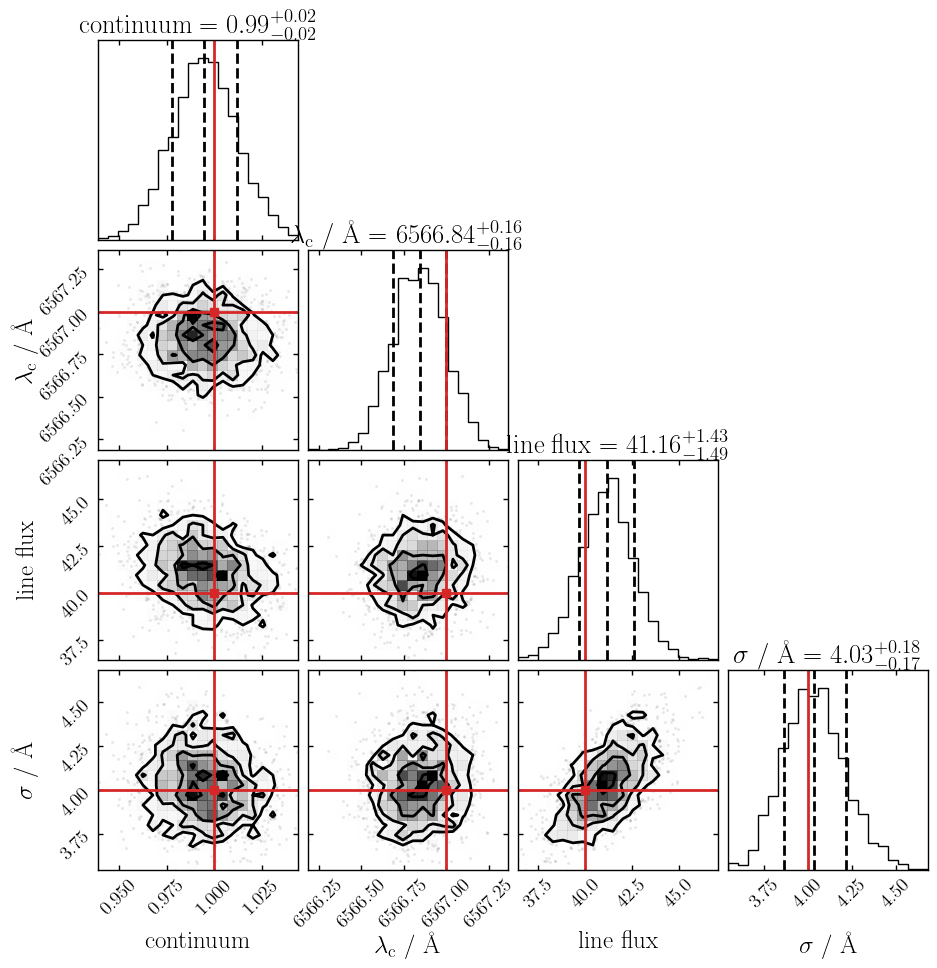

In [8]:
import corner

labels = [r"continuum", r"$\lambda_\mathrm{c}$ / $\mathrm{\AA}$", r"line flux", r"$\sigma$ / $\mathrm{\AA}$"]
fig = corner.corner(fitter.results["samples2d"], labels=labels,
                    truths=[true_values[name] for name in fitter.params],
                    truth_color="C3", quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

## 6. Reloading saved results later

You don't need the data or the likelihood function to look at a finished fit. `bff.posterior` reads the saved `.h5` file, rebuilds the fit instructions, and draws posterior samples for each fitted parameter.

In [9]:
post = bff.posterior("mock_halpha", n_samples=500)

print("Fitted parameters:", post.params)
print("Line flux: {:.2f} ± {:.2f}".format(np.median(post.samples["line:flux"]),
                                         np.std(post.samples["line:flux"])))

Fitted parameters: ['continuum', 'line:centre', 'line:flux', 'line:sigma']
Line flux: 41.26 ± 1.55
